# Fase 2 — Engenharia de Atributos

Este notebook constrói as **features numéricas** que alimentarão os algoritmos de detecção de anomalias na Fase 3.  

### Principal avanço em relação ao TCC original (Erick, 2023)

O trabalho anterior colapsou toda a informação em 6 colunas com encoding manual muito simplificado:
- URI → `'1'` (bem formada), `'2'` (começa com `/HTTP`), `'3'` (malformada)
- Método HTTP → `'1'` (GET/POST), `'2'` (outros), `'3'` (ausente)
- País → índice inteiro de lista de aparição

Esse encoding descarta quase toda a informação semântica disponível. Aqui construímos **5 famílias de features** que capturam o significado real de cada acesso:

| Família | Features | Abordagem |
|---|---|---|
| **URI** | comprimento, profundidade, chars suspeitos, extensão, encoding | Análise léxica da URI |
| **Temporal** | hora, dia da semana, horário comercial | Parse do timestamp |
| **Comportamental por IP** | volume, diversidade, taxa de erros (janela 1h) | GroupBy com janela deslizante |
| **User Agent** | ausente, tamanho, bot conhecido, scanner | Regex e lista de referência |
| **Status e Protocolo** | família de status, método incomum, versão HTTP | Categorização |

### Saída
- `data/processed/features.parquet` — features numéricas (entrada dos modelos)
- `data/processed/logs_with_features.parquet` — dataset completo com features + colunas originais (para análise)

---
**Pré-requisito:** executar `fase1_preprocessamento.ipynb` antes deste notebook.

## 0. Dependências

In [1]:
import re
import warnings
from pathlib import Path
from urllib.parse import urlparse, parse_qs, unquote

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)

print(f'pandas : {pd.__version__}')
print(f'numpy  : {np.__version__}')

pandas : 3.0.3
numpy  : 2.4.5


## 1. Carregamento dos Dados

In [2]:
# ── Caminhos ──────────────────────────────────────────────────────────────────
PROCESSED_DIR   = Path('../data/processed')
INPUT_FILE      = PROCESSED_DIR / 'logs_clean.parquet'
OUTPUT_FEATURES = PROCESSED_DIR / 'features.parquet'
OUTPUT_FULL     = PROCESSED_DIR / 'logs_with_features.parquet'
# ──────────────────────────────────────────────────────────────────────────────

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f'Arquivo não encontrado: {INPUT_FILE}\n'
        f'Execute fase1_preprocessamento.ipynb primeiro.'
    )

df = pd.read_parquet(INPUT_FILE)

# Garante que timestamp está com timezone UTC
if df['timestamp'].dt.tz is None:
    df['timestamp'] = df['timestamp'].dt.tz_localize('UTC')

# Ordena por timestamp — necessário para as features de janela deslizante
df = df.sort_values('timestamp').reset_index(drop=True)

print(f'Dataset carregado: {df.shape[0]:,} linhas × {df.shape[1]} colunas')
print(f'Período          : {df["timestamp"].min()} → {df["timestamp"].max()}')
print(f'Colunas          : {df.columns.tolist()}')

Dataset carregado: 2,353,220 linhas × 13 colunas
Período          : 2023-06-06 06:31:05+00:00 → 2023-06-21 06:31:16+00:00
Colunas          : ['ip', 'remote_user', 'host', 'status', 'bytes', 'referer', 'user_agent', 'x_forwarded', 'source_file', 'timestamp', 'http_method', 'uri', 'http_version']


In [3]:
# Distribuição dos métodos HTTP
method_counts = df['http_method'].value_counts()

print('=== Distribuição dos Métodos HTTP ===')
for method in ['GET', 'POST', 'HEAD', 'PUT', 'OPTIONS', 'PATCH']:
    count = method_counts.get(method, 0)
    percentage = count / len(df) * 100
    print(f'  {method:<8}: {count:>10,} ({percentage:>6.2f}%)')

=== Distribuição dos Métodos HTTP ===
  GET     :  2,327,728 ( 98.92%)
  POST    :     20,153 (  0.86%)
  HEAD    :      5,079 (  0.22%)
  PUT     :        234 (  0.01%)
  OPTIONS :         18 (  0.00%)
  PATCH   :          8 (  0.00%)


## 2. Família 1 — Features da URI

A URI é a coluna com mais informação semântica sobre a natureza de uma requisição. Extraímos features léxicas sem depender de nenhuma base de conhecimento externa.

**Rationale de cada feature:**
- URIs longas com muitos parâmetros são padrão de ataques de injeção
- Caracteres como `../`, `%00`, `<script>` são assinaturas de ataques conhecidos
- Encoding excessivo (`%XX`) é técnica de evasão de WAF
- Extensões como `.env`, `.git`, `.sql` nunca deveriam ser acessadas publicamente
- Profundidade de path muito alta indica tentativa de directory traversal

In [4]:
# ── Listas de referência ──────────────────────────────────────────────────────

# Extensões de arquivos sensíveis que nunca deveriam ser expostas publicamente
SUSPICIOUS_EXTENSIONS = frozenset({
    '.env', '.git', '.svn', '.htaccess', '.htpasswd',
    '.sql', '.bak', '.backup', '.old', '.orig', '.tmp',
    '.log', '.conf', '.config', '.cfg', '.ini',
    '.key', '.pem', '.p12', '.pfx', '.crt',
    '.sh', '.bash', '.zsh'
})

# Padrões de ataque conhecidos — presença na URI é forte sinal
ATTACK_PATTERNS = re.compile(
    r'(\.\./|\.\.\\)'            # path traversal
    r'|(%00|\x00)'               # null byte
    r'|(<script|<iframe|onerror)'  # XSS
    r'|(union.*select|select.*from|insert.*into|drop.*table)'  # SQLi
    r'|(etc/passwd|etc/shadow|proc/self)'  # LFI
    r'|(eval\(|base64_decode|system\(|exec\()'  # RCE
    r'|(/wp-admin|/wp-login|/administrator|/phpmyadmin)',  # scanner de CMS
    re.IGNORECASE
)

# Regex para sequências de percent-encoding (%XX)
PERCENT_ENCODING = re.compile(r'%[0-9A-Fa-f]{2}')

print('Listas de referência carregadas.')
print(f'  Extensões suspeitas: {len(SUSPICIOUS_EXTENSIONS)}')

Listas de referência carregadas.
  Extensões suspeitas: 24


In [5]:
def extract_uri_features(uri_series: pd.Series) -> pd.DataFrame:
    """
    Extrai features da coluna URI de forma vetorizada.
    Retorna DataFrame com uma coluna por feature.
    """
    # Separa path e query string
    # ex: '/path/to/page?q=1&id=2' → path='/path/to/page', query='q=1&id=2'
    has_query   = uri_series.str.contains('?', regex=False, na=False)
    path_only   = uri_series.str.split('?').str[0].fillna('')
    query_only  = uri_series.str.split('?').str[1].fillna('')

    # Extrai extensão do path
    # ex: '/page/file.php' → '.php'
    extension = path_only.str.extract(r'(\.[a-zA-Z0-9]{1,10})$')[0].fillna('').str.lower()

    # Contagem de segmentos de percent-encoding
    n_encoded = uri_series.str.count(r'%[0-9A-Fa-f]{2}').fillna(0)

    result = pd.DataFrame(index=uri_series.index)

    # Comprimento total da URI
    result['uri_length']         = uri_series.str.len().fillna(0).astype('int32')

    # Profundidade do path (número de '/' descontando o inicial)
    result['uri_depth']          = (path_only.str.count('/') - 1).clip(lower=0).astype('int16')

    # Comprimento da query string
    # result['uri_query_length']   = query_only.str.len().astype('int32')

    # Número de parâmetros na query string
    result['uri_param_count']    = query_only.str.count('&').add(has_query.astype(int)).astype('int16')

    # Presença de extensão suspeita
    result['uri_has_susp_ext']   = extension.isin(SUSPICIOUS_EXTENSIONS).astype('int8')

    # Presença de padrões de ataque
    result['uri_has_attack_pattern'] = uri_series.str.contains(
        ATTACK_PATTERNS, na=False
    ).astype('int8')

    # Número de sequências de percent-encoding (encoding excessivo = evasão)
    result['uri_encoded_chars']  = n_encoded.astype('int16')

    # URI decodificada ainda contém padrões de ataque?
    # (double encoding: %2527 → %27 → ')
    decoded = uri_series.apply(
        lambda u: unquote(unquote(str(u))) if isinstance(u, str) else ''
    )
    result['uri_double_encoded'] = decoded.str.contains(
        ATTACK_PATTERNS, na=False
    ).astype('int8')

    # URI é o raiz exato '/' ?
    result['uri_is_root']        = (uri_series == '/').astype('int8')

    return result


print('Calculando features da URI...')
uri_features = extract_uri_features(df['uri'])
print(f'Features da URI calculadas: {uri_features.shape[1]} colunas')
print(f'\nResumo:')
display(uri_features.describe().T[['mean', 'std', 'min', 'max']].round(3))

Calculando features da URI...


/tmp/ipykernel_21079/1028366189.py:37: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  result['uri_has_attack_pattern'] = uri_series.str.contains(
/tmp/ipykernel_21079/1028366189.py:49: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  result['uri_double_encoded'] = decoded.str.contains(


Features da URI calculadas: 8 colunas

Resumo:


,mean,std,min,max
uri_length,79.780,128.261,1.0,6138.0
uri_depth,4.689,16.704,0.0,512.0
uri_param_count,0.257,1.047,0.0,260.0
uri_has_susp_ext,0.003,0.058,0.0,1.0
uri_has_attack_pattern,0.004,0.065,0.0,1.0
uri_encoded_chars,0.543,7.006,0.0,385.0
uri_double_encoded,0.005,0.067,0.0,1.0
uri_is_root,0.026,0.158,0.0,1.0


In [6]:
# Análise: quantos registros têm padrões de ataque?
n_attack = uri_features['uri_has_attack_pattern'].sum()
n_susp   = uri_features['uri_has_susp_ext'].sum()
n_enc    = (uri_features['uri_encoded_chars'] > 5).sum()

print('=== URIs com sinais de ataque ===')
print(f'  Padrões de ataque detectados : {n_attack:>8,}  ({n_attack/len(df)*100:.2f}%)')
print(f'  Extensão suspeita            : {n_susp:>8,}  ({n_susp/len(df)*100:.2f}%)')
print(f'  Encoding excessivo (>5 seqs) : {n_enc:>8,}  ({n_enc/len(df)*100:.2f}%)')

# Exemplos de URIs com padrões de ataque
if n_attack > 0:
    print('\nExemplos de URIs com padrões de ataque:')
    display(
        df.loc[uri_features['uri_has_attack_pattern'] == 1, ['ip', 'host', 'uri', 'status']]
        .head(10)
        .assign(uri=lambda d: d['uri'].str[:80])
    )

=== URIs com sinais de ataque ===
  Padrões de ataque detectados :   10,019  (0.43%)
  Extensão suspeita            :    7,914  (0.34%)
  Encoding excessivo (>5 seqs) :   23,726  (1.01%)

Exemplos de URIs com padrões de ataque:


,ip,host,uri,status
32,185.220.101.8,eci.uem.br,/wp-login.php,301
105,140.99.124.133,www.dfe.uem.br,/wp-login.php?action=register,404
106,140.99.124.133,www.dfe.uem.br,/wp-login.php?action=register,404
136,159.192.123.2,www.dfe.uem.br,/wp-login.php?action=register,404
137,159.192.123.2,www.dfe.uem.br,/wp-login.php?action=register,404
140,20.219.130.121,webgateway.uem.br,/wp-admin/css/,301
255,5.161.187.214,www.dfe.uem.br,/wp-login.php?action=register,404
256,5.161.187.214,www.dfe.uem.br,/wp-login.php?action=register,404
386,201.91.82.155,www.dfe.uem.br,/wp-login.php?action=register,404
1249,94.230.208.147,www.profletras.uem.br,/wp-login.php,404


In [7]:
# ============================================================
# Top 5 — URIs mais longas
# ============================================================

df_uri_analysis = df[['ip', 'timestamp', 'host', 'http_method',
                      'status', 'uri']].copy()

df_uri_analysis['uri_length'] = uri_features['uri_length']
df_uri_analysis['uri_depth'] = uri_features['uri_depth']
df_uri_analysis['uri_param_count'] = uri_features['uri_param_count']

print('=== TOP 5 URIs MAIS LONGAS ===')

display(
    df_uri_analysis
    .nlargest(5, 'uri_length')
    [['ip', 'timestamp', 'host', 'http_method',
      'status', 'uri_length', 'uri_depth',
      'uri_param_count', 'uri']]
    .reset_index(drop=True)
)

=== TOP 5 URIs MAIS LONGAS ===


,ip,timestamp,host,http_method,status,uri_length,uri_depth,uri_param_count,uri
0,43.131.49.250,2023-06-19 08:29:59+00:00,treach.net,GET,301,6138,3,42,https://treach.net/contact-us-2/?userName=jane...
1,35.222.201.254,2023-06-20 13:09:29+00:00,www.uem.br,GET,200,3657,0,260,/@@search?sort_order=reverse&amp;sort_on=Date&...
2,35.222.201.254,2023-06-20 13:12:01+00:00,www.uem.br,GET,200,3657,0,260,/@@search?sort_order=reverse&amp;amp:list=&amp...
3,35.222.201.254,2023-06-20 13:10:48+00:00,www.uem.br,GET,200,3644,0,259,/@@search?sort_on=sortable_title&amp;amp:list=...
4,35.222.201.254,2023-06-20 13:10:10+00:00,www.uem.br,GET,200,3639,0,259,/@@search?sort_on=relevance&amp;amp:list=&amp;...


In [8]:
# ============================================================
# Top 5 — URIs com maior profundidade
# ============================================================

print('=== TOP 5 URIs COM MAIOR PROFUNDIDADE ===')

display(
    df_uri_analysis
    .nlargest(5, 'uri_depth')
    [['ip', 'timestamp', 'host', 'status',
      'uri_depth', 'uri_length', 'uri']]
    .reset_index(drop=True)
)

=== TOP 5 URIs COM MAIOR PROFUNDIDADE ===


,ip,timestamp,host,status,uri_depth,uri_length,uri
0,65.108.99.49,2023-06-10 11:04:27+00:00,www.uem.br,200,512,2066,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
1,65.108.99.49,2023-06-10 11:04:25+00:00,www.uem.br,200,511,2062,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
2,65.108.99.49,2023-06-10 11:04:22+00:00,www.uem.br,200,510,2058,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
3,65.108.99.49,2023-06-10 11:04:20+00:00,www.uem.br,200,509,2054,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
4,65.108.99.49,2023-06-10 11:04:17+00:00,www.uem.br,200,508,2050,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...


## 3. Família 2 — Features Temporais

O timestamp carrega informação sobre o **contexto** de uma requisição. Tráfego de madrugada em um servidor universitário é intrinsecamente mais suspeito que tráfego das 10h da manhã — bots e scanners automatizados não respeitam horário comercial.

In [9]:
def extract_temporal_features(ts_series: pd.Series) -> pd.DataFrame:
    """
    Extrai features temporais a partir da coluna timestamp.
    Converte para horário de Brasília (UTC-3) antes de extrair.
    """
    # Converte para horário de Brasília para que hora do dia faça sentido
    ts_local = ts_series.dt.tz_convert('America/Sao_Paulo')

    result = pd.DataFrame(index=ts_series.index)

    result['hour_of_day']       = ts_local.dt.hour.astype('int8')
    result['day_of_week']       = ts_local.dt.dayofweek.astype('int8')  # 0=seg, 6=dom
    result['is_weekend']        = (ts_local.dt.dayofweek >= 5).astype('int8')

    # Horário comercial: seg-sex das 8h às 18h
    is_weekday      = ts_local.dt.dayofweek < 5
    is_work_hour    = ts_local.dt.hour.between(8, 17)
    result['is_business_hours'] = (is_weekday & is_work_hour).astype('int8')

    # Período do dia: madrugada (0), manhã (1), tarde (2), noite (3)
    # Útil para modelos que não entendem ciclicidade da hora
    hour = ts_local.dt.hour
    # result['time_period'] = pd.cut(
    #     hour,
    #     bins=[-1, 5, 11, 17, 23],
    #     labels=[0, 1, 2, 3]   # 0=madrugada, 1=manhã, 2=tarde, 3=noite
    # ).astype('int8')

    # Encoding cíclico da hora — preserva que hora 23 e hora 0 são próximas
    # Modelos de ML não sabem que hora é circular sem esse encoding
    result['hour_sin'] = np.sin(2 * np.pi * hour / 24).astype('float32')
    result['hour_cos'] = np.cos(2 * np.pi * hour / 24).astype('float32')

    # Encoding cíclico do dia da semana
    dow = ts_local.dt.dayofweek
    result['dow_sin']  = np.sin(2 * np.pi * dow / 7).astype('float32')
    result['dow_cos']  = np.cos(2 * np.pi * dow / 7).astype('float32')

    return result


print('Calculando features temporais...')
temporal_features = extract_temporal_features(df['timestamp'])
print(f'Features temporais calculadas: {temporal_features.shape[1]} colunas')
display(temporal_features.describe().T[['mean', 'min', 'max']].round(3))

Calculando features temporais...
Features temporais calculadas: 8 colunas


,mean,min,max
hour_of_day,13.361,0.000,23.000
day_of_week,2.651,0.000,6.000
is_weekend,0.213,0.000,1.000
is_business_hours,0.473,0.000,1.000
hour_sin,-0.188,-1.000,1.000
hour_cos,-0.197,-1.000,1.000
dow_sin,0.036,-0.975,0.975
dow_cos,0.046,-0.901,1.000


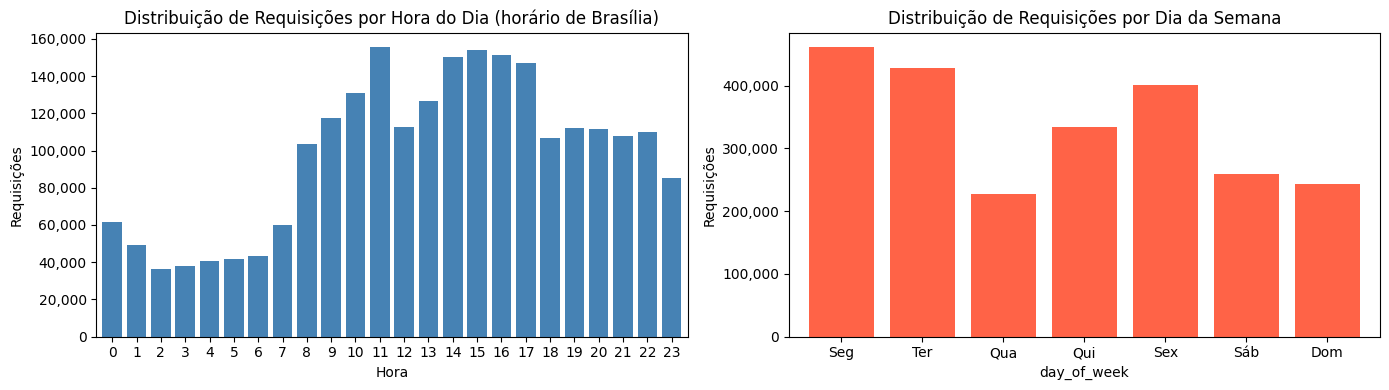

Figura salva em data/processed/fig_03_temporal.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribuição por hora do dia
temporal_features['hour_of_day'].value_counts().sort_index().plot.bar(
    ax=axes[0], color='steelblue', edgecolor='none', width=0.8
)
axes[0].set_title('Distribuição de Requisições por Hora do Dia (horário de Brasília)')
axes[0].set_xlabel('Hora')
axes[0].set_ylabel('Requisições')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].tick_params(axis='x', rotation=0)

# Distribuição por dia da semana
dow_labels = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
temporal_features['day_of_week'].value_counts().sort_index().plot.bar(
    ax=axes[1], color='tomato', edgecolor='none', width=0.8
)
axes[1].set_title('Distribuição de Requisições por Dia da Semana')
axes[1].set_xticklabels(dow_labels, rotation=0)
axes[1].set_ylabel('Requisições')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_03_temporal.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura salva em data/processed/fig_03_temporal.png')

temporal_features = temporal_features.drop(columns=['hour_of_day'])
temporal_features = temporal_features.drop(columns=['day_of_week'])

## 4. Família 3 — Features Comportamentais por IP (janela de 1 hora)

Esta é a família mais importante e a principal contribuição técnica deste trabalho em relação ao TCC anterior.

**Por que é importante:** Um único acesso a uma URI suspeita pode ser acidental. Mas 500 acessos a URIs suspeitas na mesma hora, para 50 hosts diferentes, com 80% de erro 404, é inegavelmente um scanner. O comportamento temporal de um IP revela intenção que nenhuma feature de requisição individual consegue capturar.

**Implementação:** Para cada requisição no instante `t`, calculamos estatísticas do mesmo IP na janela `[t-1h, t)` — excluindo a requisição atual para evitar data leakage. Usamos `merge_asof` e `groupby` com `transform`, sem loops Python.

In [11]:
def compute_ip_window_features(df: pd.DataFrame, window_hours: int = 1) -> pd.DataFrame:
    """
    Calcula features comportamentais por IP, em abordagem híbrida:

    - req_count, error_rate, post_rate: janela ROLANTE verdadeira
      [t - window_hours, t), ancorada no timestamp de cada requisição
      (closed='left' exclui a própria requisição -> sem data leakage).
      Escolhidas por serem vetorizáveis via rolling e por serem as
      features mais sensíveis a rajadas curtas (ex.: DoS), que ficavam
      "cegas" na abordagem por hora-relógio fixa + shift(1).

    - distinct_hosts, uri_diversity: mantidas na abordagem original
      (janela de hora-relógio fixa + shift(1) por IP), pois dependem
      de nunique() por IP, que o rolling do pandas não vetoriza --
      exigiria .apply() por grupo, inviável no volume do dataset (2M+
      registros). O trade-off é uma latência de detecção maior para
      essas duas (só refletem o comportamento na hora seguinte), mas
      isso é aceitável: diversidade de hosts/URIs tende a ser um sinal
      mais estável ao longo de várias horas, diferente de picos de
      volume, que são o alvo principal desta correção.
    """
    print(f'  Calculando janelas rolantes ({window_hours}h) + hora-cheia por IP...')

    df_work = df[['ip', 'timestamp', 'host', 'uri', 'status', 'http_method']].copy()
    df_work = df_work.reset_index(drop=False).rename(columns={'index': '_orig_idx'})

    # ════════════════════════════════════════════════════════════════════
    # PARTE A — Features de volume/taxa: janela ROLANTE real
    # ════════════════════════════════════════════════════════════════════
    df_sorted = df_work.sort_values(['ip', 'timestamp']).copy()
    df_sorted['is_4xx_5xx'] = (df_sorted['status'] // 100).isin([4, 5]).astype('int32')
    df_sorted['is_post']    = (df_sorted['http_method'] == 'POST').astype('int32')

    df_idx = df_sorted.set_index('timestamp')
    win = f'{window_hours}h'

    # closed='left' => janela [t-window, t), NUNCA inclui a própria requisição
    roll_count  = df_idx.groupby('ip')['is_4xx_5xx'].rolling(win, closed='left').count()
    roll_errors = df_idx.groupby('ip')['is_4xx_5xx'].rolling(win, closed='left').sum()
    roll_post   = df_idx.groupby('ip')['is_post'].rolling(win, closed='left').sum()

    df_sorted['ip_req_count_prev1h']  = roll_count.values
    df_sorted['ip_error_rate_prev1h'] = (roll_errors.values / roll_count.values)
    df_sorted['ip_post_rate_prev1h']  = (roll_post.values / roll_count.values)

    # Primeira(s) requisição(ões) de cada IP: sem histórico -> 0
    for c in ['ip_req_count_prev1h', 'ip_error_rate_prev1h', 'ip_post_rate_prev1h']:
        df_sorted[c] = df_sorted[c].fillna(0)

    rolling_feats = df_sorted[['_orig_idx', 'ip_req_count_prev1h',
                                'ip_error_rate_prev1h', 'ip_post_rate_prev1h']]

    # ════════════════════════════════════════════════════════════════════
    # PARTE B — distinct_hosts, uri_diversity: hora-cheia + shift(1) (original)
    # ════════════════════════════════════════════════════════════════════
    df_work['window'] = df_work['timestamp'].dt.floor(f'{window_hours}h')
    grp = df_work.groupby(['ip', 'window'])

    agg = grp.agg(
        req_count      = ('uri',  'count'),
        distinct_hosts = ('host', 'nunique'),
        distinct_uris  = ('uri',  'nunique'),
    ).reset_index()

    agg['uri_diversity'] = agg['distinct_uris'] / agg['req_count']
    agg = agg.drop(columns=['distinct_uris'])

    agg = agg.sort_values(['ip', 'window'])
    feature_cols = ['distinct_hosts', 'uri_diversity']
    agg_shifted = agg.copy()
    agg_shifted[feature_cols] = (
        agg.groupby('ip')[feature_cols]
        .shift(1)
        .fillna(0)
    )
    rename_map = {c: f'ip_{c}_prev1h' for c in feature_cols}
    agg_shifted = agg_shifted.rename(columns=rename_map)

    hourly_feats = df_work[['_orig_idx', 'ip', 'window']].merge(
        agg_shifted[['ip', 'window'] + list(rename_map.values())],
        on=['ip', 'window'],
        how='left'
    )[['_orig_idx'] + list(rename_map.values())]
    hourly_feats[list(rename_map.values())] = hourly_feats[list(rename_map.values())].fillna(0)

    # ════════════════════════════════════════════════════════════════════
    # Junta as duas partes, restaura ordem original
    # ════════════════════════════════════════════════════════════════════
    result = rolling_feats.merge(hourly_feats, on='_orig_idx', how='left')
    result = result.sort_values('_orig_idx').drop(columns=['_orig_idx']).reset_index(drop=True)

    # Reordena colunas como no original
    result = result[[
        'ip_req_count_prev1h', 'ip_distinct_hosts_prev1h',
        'ip_error_rate_prev1h', 'ip_post_rate_prev1h', 'ip_uri_diversity_prev1h'
    ]]

    for col in result.columns:
        if 'rate' in col or 'diversity' in col:
            result[col] = result[col].astype('float32')
        else:
            result[col] = result[col].astype('int32')

    print(f'  Concluído. Features geradas: {result.shape[1]} colunas')
    return result

print('Calculando features comportamentais por IP...')
ip_features = compute_ip_window_features(df, window_hours=1)
print(f'\nResumo:')
display(ip_features.describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))

Calculando features comportamentais por IP...
  Calculando janelas rolantes (1h) + hora-cheia por IP...
  Concluído. Features geradas: 5 colunas

Resumo:


,mean,std,min,50%,max
ip_req_count_prev1h,397.533,1866.486,0.0,14.0,20514.0
ip_distinct_hosts_prev1h,3.494,10.588,0.0,1.0,95.0
ip_error_rate_prev1h,0.098,0.213,0.0,0.0,1.0
ip_post_rate_prev1h,0.006,0.062,0.0,0.0,1.0
ip_uri_diversity_prev1h,0.478,0.456,0.0,0.5,1.0


=== IPs com maior volume na janela anterior (top 10) ===


,ip,timestamp,ip_req_count_prev1h,ip_error_rate_prev1h
0,45.71.104.191,2023-06-09 20:42:17+00:00,20514,0.995564
1,45.71.104.191,2023-06-09 20:42:14+00:00,20509,0.995807
2,45.71.104.191,2023-06-09 20:42:14+00:00,20509,0.995807
3,45.71.104.191,2023-06-09 20:42:14+00:00,20509,0.995807
4,45.71.104.191,2023-06-09 20:42:14+00:00,20509,0.995807
5,45.71.104.191,2023-06-09 20:42:14+00:00,20509,0.995807
6,45.71.104.191,2023-06-09 20:42:13+00:00,20498,0.996195
7,45.71.104.191,2023-06-09 20:42:13+00:00,20498,0.996195
8,45.71.104.191,2023-06-09 20:42:13+00:00,20498,0.996195
9,45.71.104.191,2023-06-09 20:42:13+00:00,20498,0.996195


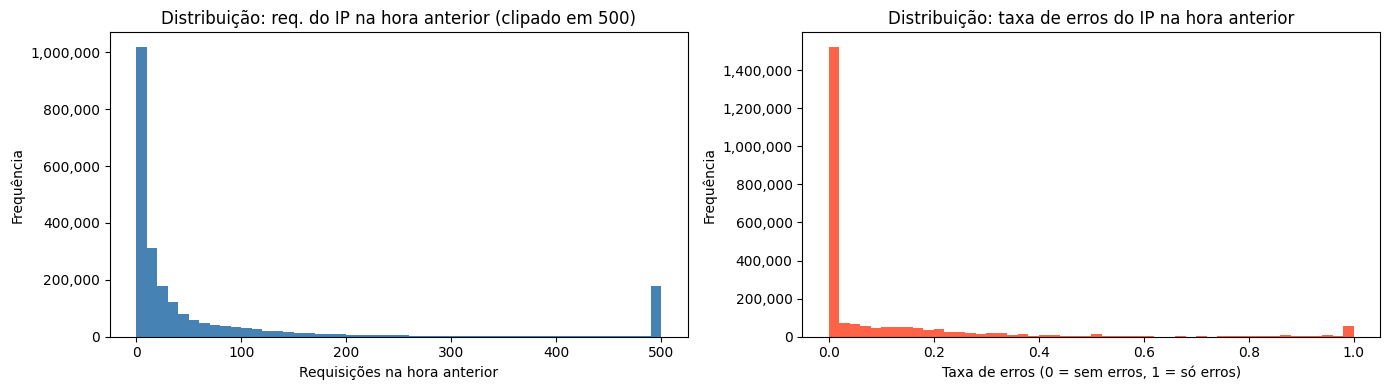

In [12]:
# Análise: IPs com maior volume na janela anterior
df_ip_analysis = df[['ip', 'timestamp']].copy()
df_ip_analysis['ip_req_count_prev1h'] = ip_features['ip_req_count_prev1h']
df_ip_analysis['ip_error_rate_prev1h'] = ip_features['ip_error_rate_prev1h']

print('=== IPs com maior volume na janela anterior (top 10) ===')
display(
    df_ip_analysis
    .nlargest(10, 'ip_req_count_prev1h')[['ip', 'timestamp', 'ip_req_count_prev1h', 'ip_error_rate_prev1h']]
    .reset_index(drop=True)
)

# print('=== IPs com mais hosts na janela anterior (top 10) ===')
# display(
#     df_ip_analysis
#     .nlargest(10, 'ip_distinct_hosts_prev1h')[['ip', 'timestamp', 'ip_req_count_prev1h', 'ip_error_rate_prev1h']]
#     .reset_index(drop=True)
# )

# Distribuição da taxa de erros por IP
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ip_features['ip_req_count_prev1h'].clip(upper=500).plot.hist(
    ax=axes[0], bins=50, color='steelblue', edgecolor='none'
)
axes[0].set_title('Distribuição: req. do IP na hora anterior (clipado em 500)')
axes[0].set_xlabel('Requisições na hora anterior')
axes[0].set_ylabel('Frequência')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

ip_features['ip_error_rate_prev1h'].plot.hist(
    ax=axes[1], bins=50, color='tomato', edgecolor='none'
)
axes[1].set_title('Distribuição: taxa de erros do IP na hora anterior')
axes[1].set_xlabel('Taxa de erros (0 = sem erros, 1 = só erros)')
axes[1].set_ylabel('Frequência')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_04_ip_behavior.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. Família 4 — Features do User Agent

O User Agent é autodeclarado — qualquer cliente pode forjar qualquer UA. Mas na prática, ferramentas de ataque frequentemente usam UAs padrão reconhecíveis, não enviam UA algum, ou enviam UAs claramente não-browser. A ausência de UA é especialmente informativa: bots legítimos sempre se identificam (Googlebot, bingbot), enquanto scanners maliciosos frequentemente não enviam UA.

In [13]:
# ── Listas de referência para User Agent ─────────────────────────────────────

# Bots legítimos e bem conhecidos (identificam-se explicitamente)
KNOWN_BOTS = re.compile(
    r'(googlebot|bingbot|yandexbot|duckduckbot|baiduspider'
    r'|sogou|exabot|facebot|facebookexternalhit'
    r'|twitterbot|linkedinbot|slackbot|whatsapp'
    r'|seekportbot|semrushbot|ahrefsbot|mj12bot'
    r'|dotbot|petalbot|bytespider|gptbot'
    r'|applebot|pinterest|tumblr|discobot'
    r'|wayback|archive\.org|ia_archiver'
    r'|collectd|nagios|zabbix|prometheus)',
    re.IGNORECASE
)

# Ferramentas de ataque, scan e reconhecimento
KNOWN_SCANNERS = re.compile(
    r'(nikto|sqlmap|nmap|masscan|zgrab|nuclei'
    r'|dirbuster|gobuster|wfuzz|hydra|medusa'
    r'|metasploit|burpsuite|w3af|acunetix'
    r'|nessus|openvas|qualys|rapid7'
    r'|python-requests|go-http-client|libwww-perl'
    r'|curl/|wget/|httpie|java/|okhttp'
    r'|zgrab|masscan|shodan|censys)',
    re.IGNORECASE
)

# Browsers legítimos
BROWSER_PATTERN = re.compile(
    r'(mozilla|chrome|firefox|safari|opera|edge|trident)',
    re.IGNORECASE
)

print('Padrões de User Agent carregados.')

Padrões de User Agent carregados.


In [14]:
def extract_ua_features(ua_series: pd.Series) -> pd.DataFrame:
    """
    Extrai features do campo User-Agent.
    """
    is_missing = (ua_series == '-') | ua_series.isna()
    ua_filled  = ua_series.fillna('-')

    result = pd.DataFrame(index=ua_series.index)

    # Ausência de UA — forte sinal de scanner/bot malicioso
    result['ua_is_missing']      = is_missing.astype('int8')

    # Comprimento do UA (UAs legítimos são longos; ausentes têm comprimento 1)
    result['ua_length']          = ua_filled.str.len().astype('int16')

    # Bot legítimo e bem comportado
    result['ua_is_known_bot']    = (
        ~is_missing & ua_filled.str.contains(KNOWN_BOTS, na=False)
    ).astype('int8')

    # Ferramenta de scan/ataque conhecida
    result['ua_is_scanner']      = (
        ~is_missing & ua_filled.str.contains(KNOWN_SCANNERS, na=False)
    ).astype('int8')

    # Browser legítimo (humano ou bot que imita humano)
    result['ua_is_browser']      = (
        ~is_missing & ua_filled.str.contains(BROWSER_PATTERN, na=False)
    ).astype('int8')

    # UA não classificado em nenhuma categoria conhecida
    result['ua_is_unknown_type'] = (
        ~is_missing
        & (result['ua_is_known_bot'] == 0)
        & (result['ua_is_scanner']   == 0)
        & (result['ua_is_browser']   == 0)
    ).astype('int8')

    return result


print('Calculando features de User Agent...')
ua_features = extract_ua_features(df['user_agent'])
print(f'Features de UA calculadas: {ua_features.shape[1]} colunas')
print()

total = len(df)
for col in ua_features.columns:
    n = ua_features[col].sum() if col != 'ua_length' else None
    if n is not None:
        print(f'  {col:<25s}: {n:>8,}  ({n/total*100:.1f}%)')
    else:
        print(f'  {col:<25s}: média={ua_features[col].mean():.1f}, max={ua_features[col].max()}')

Calculando features de User Agent...


/tmp/ipykernel_21079/3618190788.py:18: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~is_missing & ua_filled.str.contains(KNOWN_BOTS, na=False)
/tmp/ipykernel_21079/3618190788.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~is_missing & ua_filled.str.contains(KNOWN_SCANNERS, na=False)
/tmp/ipykernel_21079/3618190788.py:28: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ~is_missing & ua_filled.str.contains(BROWSER_PATTERN, na=False)


Features de UA calculadas: 6 colunas

  ua_is_missing            :    2,261  (0.1%)
  ua_length                : média=107.7, max=558
  ua_is_known_bot          :  472,507  (20.1%)
  ua_is_scanner            :   49,345  (2.1%)
  ua_is_browser            : 2,189,133  (93.0%)
  ua_is_unknown_type       :   71,777  (3.1%)


## 6. Família 5 — Features de Status HTTP e Protocolo

O status HTTP e o método/versão do protocolo são os campos mais estruturados do log — fáceis de extrair, mas importantes para contextualizar o tipo de acesso.

In [15]:
def extract_protocol_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Extrai features de status HTTP, método e versão do protocolo.
    """
    result = pd.DataFrame(index=df.index)

    # Família de status: 2→sucesso, 3→redirecionamento, 4→erro cliente, 5→erro servidor
    result['status_family']      = (df['status'] // 100).astype('int8')

    # Flags de status específicos
    #result['is_success']         = (df['status'].between(200, 299)).astype('int8')
    result['is_redirect']        = (df['status'].between(300, 399)).astype('int8')
    result['is_client_error']    = (df['status'].between(400, 499)).astype('int8')
    result['is_server_error']    = (df['status'] >= 500).astype('int8')
    result['is_forbidden']       = (df['status'] == 403).astype('int8')
    #result['is_not_found']       = (df['status'] == 404).astype('int8')
    result['is_timeout']         = (df['status'].isin([408, 499, 504])).astype('int8')

    # Resposta com zero bytes — suspeito (conexão interrompida, evasão)
    result['bytes_is_zero']      = (df['bytes'] == 0).astype('int8')

    # Log do volume de bytes (comprime a cauda longa)
    result['bytes_log']          = np.log1p(df['bytes'].astype('float32')).astype('float32')

    # Método HTTP
    result['method_is_get']      = (df['http_method'] == 'GET').astype('int8')
    result['method_is_post']     = (df['http_method'] == 'POST').astype('int8')
    #result['method_is_connect']  = (df['http_method'] == 'CONNECT').astype('int8')
    result['method_is_unusual']  = (
        ~df['http_method'].isin(['GET', 'POST', 'HEAD'])
    ).astype('int8')

    # Versão HTTP
    # HTTP/1.0 é mais antigo e menos comum em browsers modernos — mais frequente em bots
    result['version_is_http10']  = (df['http_version'] == 'HTTP/1.0').astype('int8')
    #result['version_is_http11']  = (df['http_version'] == 'HTTP/1.1').astype('int8')
    #result['version_is_http2']   = (df['http_version'] == 'HTTP/2.0').astype('int8')
    #result['version_is_unknown'] = (df['http_version'] == 'UNKNOWN').astype('int8')

    # Status HTTP como valor numérico direto (para modelos que usam o número)
    #result['status_code']        = df['status'].astype('int16')

    return result


print('Calculando features de status e protocolo...')
protocol_features = extract_protocol_features(df)
print(f'Features de protocolo calculadas: {protocol_features.shape[1]} colunas')
display(protocol_features.describe().T[['mean', 'min', 'max']].round(3))

Calculando features de status e protocolo...
Features de protocolo calculadas: 12 colunas


,mean,min,max
status_family,2.327,2.0,5.000
is_redirect,0.035,0.0,1.000
is_client_error,0.144,0.0,1.000
is_server_error,0.001,0.0,1.000
is_forbidden,0.000,0.0,1.000
is_timeout,0.001,0.0,1.000
bytes_is_zero,0.012,0.0,1.000
bytes_log,8.390,0.0,18.831
method_is_get,0.989,0.0,1.000
method_is_post,0.009,0.0,1.000


## 7. Consolidação do Dataset de Features

In [16]:
# Concatena todas as famílias de features
features = pd.concat(
    [uri_features, temporal_features, ip_features, ua_features, protocol_features],
    axis=1
)

assert len(features) == len(df), 'Divergência no número de linhas!'
assert features.isnull().sum().sum() == 0, f'Nulos encontrados: {features.isnull().sum()[features.isnull().sum()>0]}'

print(f'Dataset de features consolidado:')
print(f'  Linhas    : {len(features):,}')
print(f'  Features  : {len(features.columns)}')
print()
print('Colunas por família:')
print(f'  URI                : {len(uri_features.columns):>3} features')
print(f'  Temporal           : {len(temporal_features.columns):>3} features')
print(f'  Comportamental IP  : {len(ip_features.columns):>3} features')
print(f'  User Agent         : {len(ua_features.columns):>3} features')
print(f'  Protocolo/Status   : {len(protocol_features.columns):>3} features')
print(f'  {"─"*25}')
print(f'  Total              : {len(features.columns):>3} features')

Dataset de features consolidado:
  Linhas    : 2,353,220
  Features  : 37

Colunas por família:
  URI                :   8 features
  Temporal           :   6 features
  Comportamental IP  :   5 features
  User Agent         :   6 features
  Protocolo/Status   :  12 features
  ─────────────────────────
  Total              :  37 features


In [17]:
print('Todas as features:')
for i, col in enumerate(features.columns, 1):
    print(f'  {i:2d}. {col:<35s}  dtype={features[col].dtype}')

Todas as features:
   1. uri_length                           dtype=int32
   2. uri_depth                            dtype=int16
   3. uri_param_count                      dtype=int16
   4. uri_has_susp_ext                     dtype=int8
   5. uri_has_attack_pattern               dtype=int8
   6. uri_encoded_chars                    dtype=int16
   7. uri_double_encoded                   dtype=int8
   8. uri_is_root                          dtype=int8
   9. is_weekend                           dtype=int8
  10. is_business_hours                    dtype=int8
  11. hour_sin                             dtype=float32
  12. hour_cos                             dtype=float32
  13. dow_sin                              dtype=float32
  14. dow_cos                              dtype=float32
  15. ip_req_count_prev1h                  dtype=int32
  16. ip_distinct_hosts_prev1h             dtype=int32
  17. ip_error_rate_prev1h                 dtype=float32
  18. ip_post_rate_prev1h                 

## 8. Análise Exploratória das Features

Antes de passar para a modelagem, é importante entender a distribuição das features e identificar possíveis problemas como variância zero ou correlações extremas.

In [18]:
# Features com variância zero (inúteis para modelos)
zero_var = features.columns[features.std() == 0].tolist()
if zero_var:
    print(f'⚠ Features com variância zero (serão removidas): {zero_var}')
    features = features.drop(columns=zero_var)
    print(f'  Features restantes: {len(features.columns)}')
else:
    print('✓ Nenhuma feature com variância zero.')

✓ Nenhuma feature com variância zero.


In [19]:
# Matriz de correlação — identifica features redundantes
# Features binárias e contínuas são analisadas juntas
corr = features.corr(method='spearman')  # Spearman é mais robusto para features não-normais

# Pares de features com correlação > 0.95 (redundância)
high_corr_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.95:
            high_corr_pairs.append((
                corr.columns[i], corr.columns[j], round(corr.iloc[i, j], 3)
            ))

if high_corr_pairs:
    print(f'Pares com correlação Spearman > 0.95 (possível redundância):')
    for a, b, r in high_corr_pairs:
        print(f'  {a}  ↔  {b}  (r={r})')
else:
    print('✓ Nenhum par de features com correlação > 0.95.')

Pares com correlação Spearman > 0.95 (possível redundância):
  uri_has_attack_pattern  ↔  uri_double_encoded  (r=0.967)


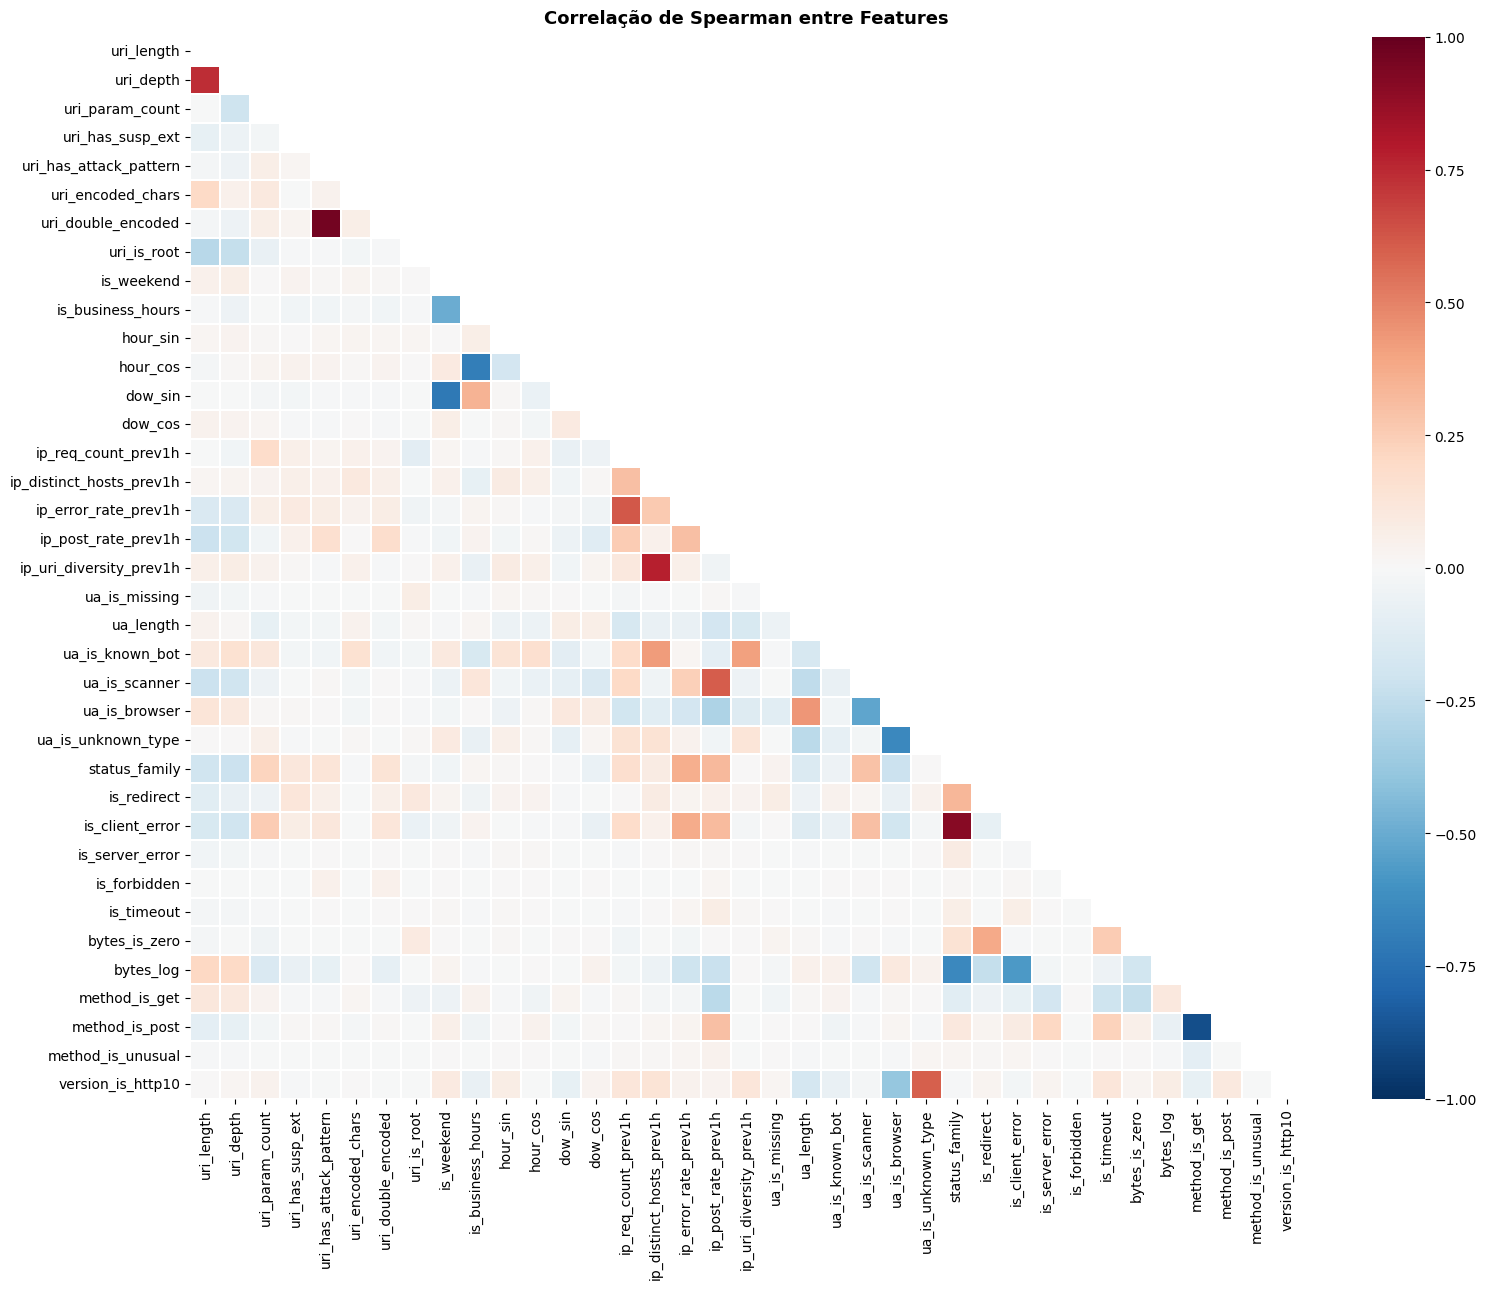

Figura salva em data/processed/fig_05_correlation.png


In [20]:
# Heatmap de correlação
fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))  # mostra só triângulo inferior

sns.heatmap(
    corr,
    mask=mask,
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    annot=False,
    linewidths=0.3,
    ax=ax
)
ax.set_title('Correlação de Spearman entre Features', fontsize=13, fontweight='bold', pad=10)
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_05_correlation.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura salva em data/processed/fig_05_correlation.png')

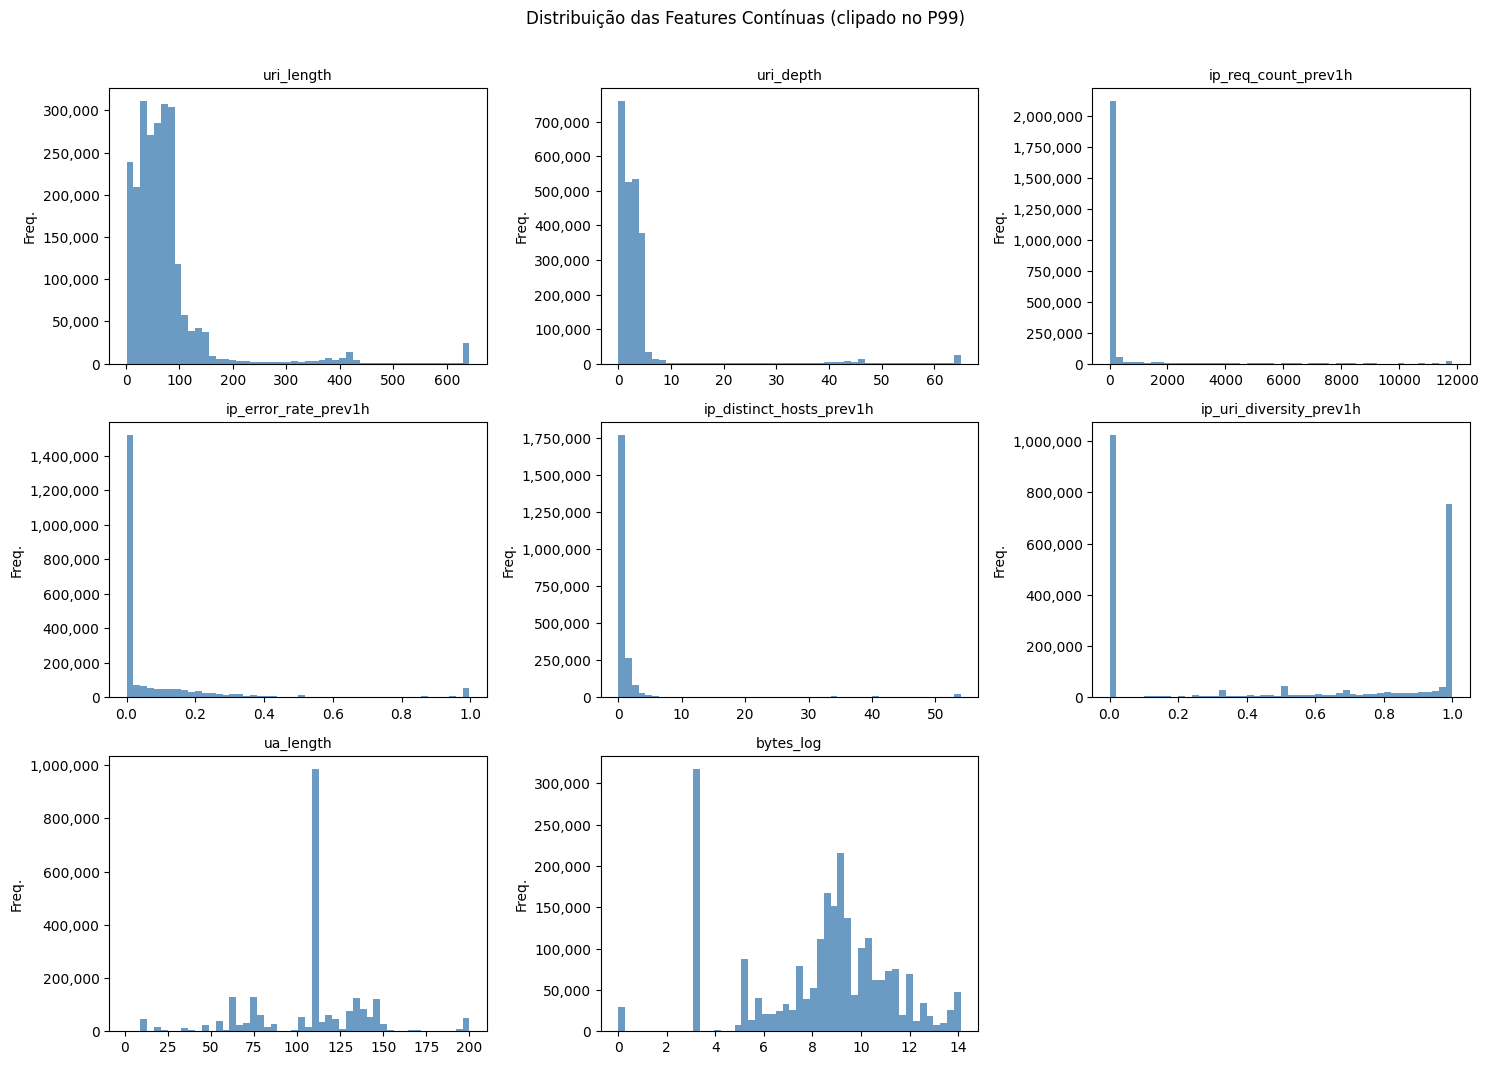

Figura salva em data/processed/fig_06_distributions.png


In [21]:
# Distribuição das features numéricas contínuas
continuous_cols = [
    'uri_length', 'uri_depth', 'uri_query_length',
    'ip_req_count_prev1h', 'ip_error_rate_prev1h',
    'ip_distinct_hosts_prev1h', 'ip_uri_diversity_prev1h',
    'ua_length', 'bytes_log'
]
# Filtra apenas as que existem
continuous_cols = [c for c in continuous_cols if c in features.columns]

n_cols = 3
n_rows = (len(continuous_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    data = features[col].clip(
        upper=features[col].quantile(0.99)  # Clipagem no P99 para melhor visualização
    )
    axes[i].hist(data, bins=50, color='steelblue', edgecolor='none', alpha=0.8)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Freq.')
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Esconde eixos vazios
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribuição das Features Contínuas (clipado no P99)', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_06_distributions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura salva em data/processed/fig_06_distributions.png')

## 9. Persistência

In [22]:
# ── Salva apenas as features (entrada dos modelos da Fase 3) ──────────────────
features.to_parquet(OUTPUT_FEATURES, index=False, compression='snappy')
size_feat = OUTPUT_FEATURES.stat().st_size / 1024 / 1024
print(f'✓ Features salvas em   : {OUTPUT_FEATURES}')
print(f'  Tamanho              : {size_feat:.1f} MB')
print(f'  Linhas × Features    : {features.shape[0]:,} × {features.shape[1]}')

✓ Features salvas em   : ../data/processed/features.parquet
  Tamanho              : 20.0 MB
  Linhas × Features    : 2,353,220 × 37


In [23]:
# ── Salva dataset completo (features + colunas originais para análise) ─────────
# Útil para inspecionar quais requisições foram marcadas como anomalia na Fase 3
logs_with_features = pd.concat([df.reset_index(drop=True), features], axis=1)
logs_with_features.to_parquet(OUTPUT_FULL, index=False, compression='snappy')
size_full = OUTPUT_FULL.stat().st_size / 1024 / 1024
print(f'✓ Dataset completo salvo: {OUTPUT_FULL}')
print(f'  Tamanho               : {size_full:.1f} MB')
print(f'  Linhas × Colunas      : {logs_with_features.shape[0]:,} × {logs_with_features.shape[1]}')

✓ Dataset completo salvo: ../data/processed/logs_with_features.parquet
  Tamanho               : 94.6 MB
  Linhas × Colunas      : 2,353,220 × 50


In [24]:
# Verificação de integridade
f_check = pd.read_parquet(OUTPUT_FEATURES)
assert f_check.shape == features.shape
assert f_check.isnull().sum().sum() == 0
print(f'✓ Verificação OK: {f_check.shape[0]:,} linhas × {f_check.shape[1]} features, zero nulos.')

✓ Verificação OK: 2,353,220 linhas × 37 features, zero nulos.


## 10. Resumo da Fase 2

In [27]:
# ============================================================
# Top 10 — URIs mais longas
# ============================================================

df_uri_analysis = df[['ip', 'timestamp', 'host', 'http_method',
                      'status', 'uri']].copy()

df_uri_analysis['uri_length'] = uri_features['uri_length']
df_uri_analysis['uri_depth'] = uri_features['uri_depth']
df_uri_analysis['uri_param_count'] = uri_features['uri_param_count']

print('=== TOP 10 URIs MAIS LONGAS ===')

display(
    df_uri_analysis
    .nlargest(10, 'uri_length')
    [['ip', 'timestamp', 'host', 'http_method',
      'status', 'uri_length', 'uri_depth',
      'uri_param_count', 'uri']]
    .reset_index(drop=True)
)

# ============================================================
# Top 10 — URIs com maior profundidade
# ============================================================

print('=== TOP 10 URIs COM MAIOR PROFUNDIDADE ===')

display(
    df_uri_analysis
    .nlargest(10, 'uri_depth')
    [['ip', 'timestamp', 'host', 'status',
      'uri_depth', 'uri_length', 'uri']]
    .reset_index(drop=True)
)

# ============================================================
# Top 10 — IPs com maior taxa de acesso
# ============================================================

df_ip_analysis = df[['ip']].copy()

df_ip_analysis['req_count_prev1h'] = ip_features['ip_req_count_prev1h']
df_ip_analysis['error_rate_prev1h'] = ip_features['ip_error_rate_prev1h']
df_ip_analysis['distinct_hosts_prev1h'] = ip_features['ip_distinct_hosts_prev1h']
#df_ip_analysis['distinct_uris_prev1h'] = ip_features['ip_distinct_uris_prev1h']

# Remove duplicação: uma linha por IP
top_ips = (
    df_ip_analysis
    .groupby('ip')
    .agg(
        req_count_prev1h=('req_count_prev1h', 'max'),
        error_rate_prev1h=('error_rate_prev1h', 'max'),
        distinct_hosts_prev1h=('distinct_hosts_prev1h', 'max'),
        #distinct_uris_prev1h=('distinct_uris_prev1h', 'max')
    )
    .nlargest(10, 'req_count_prev1h')
    .reset_index()
)

print('=== TOP 10 IPs COM MAIOR VOLUME DE ACESSOS ===')

display(top_ips)

# ============================================================
# Top 10 — IPs com maior taxa de erro
# ============================================================

top_error_ips = (
    df_ip_analysis
    .groupby('ip')
    .agg(
        req_count_prev1h=('req_count_prev1h', 'max'),
        error_rate_prev1h=('error_rate_prev1h', 'max'),
        distinct_hosts_prev1h=('distinct_hosts_prev1h', 'max'),
        #distinct_uris_prev1h=('distinct_uris_prev1h', 'max')
    )
)

# Evita destacar IPs que fizeram pouquíssimas requisições
top_error_ips = (
    top_error_ips[top_error_ips['req_count_prev1h'] >= 100]
    .nlargest(10, 'error_rate_prev1h')
    .reset_index()
)

print('=== TOP 10 IPs COM MAIOR TAXA DE ERRO ===')

display(top_error_ips)

# ============================================================
# Top 10 — Casos com múltiplos indicadores suspeitos
# ============================================================

analysis = df[['ip', 'timestamp', 'host', 'status',
               'http_method', 'uri']].copy()

analysis['attack_pattern'] = uri_features['uri_has_attack_pattern']
analysis['suspicious_extension'] = uri_features['uri_has_susp_ext']
analysis['double_encoding'] = uri_features['uri_double_encoded']
analysis['scanner_ua'] = ua_features['ua_is_scanner']
analysis['missing_ua'] = ua_features['ua_is_missing']
analysis['unusual_method'] = protocol_features['method_is_unusual']

analysis['suspicious_signals'] = (
    analysis['attack_pattern'] +
    analysis['suspicious_extension'] +
    analysis['double_encoding'] +
    analysis['scanner_ua'] +
    analysis['missing_ua'] +
    analysis['unusual_method']
)

print('=== TOP 10 REQUISIÇÕES COM MAIS INDICADORES SUSPEITOS ===')

display(
    analysis
    .nlargest(20, 'suspicious_signals')
    [['ip', 'timestamp', 'host', 'status',
      'http_method', 'suspicious_signals',
      'uri']]
    .reset_index(drop=True)
)

=== TOP 10 URIs MAIS LONGAS ===


,ip,timestamp,host,http_method,status,uri_length,uri_depth,uri_param_count,uri
0,43.131.49.250,2023-06-19 08:29:59+00:00,treach.net,GET,301,6138,3,42,https://treach.net/contact-us-2/?userName=jane...
1,35.222.201.254,2023-06-20 13:09:29+00:00,www.uem.br,GET,200,3657,0,260,/@@search?sort_order=reverse&amp;sort_on=Date&...
2,35.222.201.254,2023-06-20 13:12:01+00:00,www.uem.br,GET,200,3657,0,260,/@@search?sort_order=reverse&amp;amp:list=&amp...
3,35.222.201.254,2023-06-20 13:10:48+00:00,www.uem.br,GET,200,3644,0,259,/@@search?sort_on=sortable_title&amp;amp:list=...
4,35.222.201.254,2023-06-20 13:10:10+00:00,www.uem.br,GET,200,3639,0,259,/@@search?sort_on=relevance&amp;amp:list=&amp;...
5,35.222.201.254,2023-06-20 13:08:44+00:00,www.uem.br,GET,200,2872,0,130,/search_rss?sort_on=sortable_title&amp;amp;amp...
6,35.222.201.254,2023-06-20 13:12:38+00:00,www.uem.br,GET,200,2867,0,130,/search_rss?sort_on=relevance&amp;amp;amp;amp:...
7,65.108.99.49,2023-06-10 09:04:21+00:00,www.uem.br,GET,200,2066,225,2,/eleicoes/eleicoes/eleicoes/eleicoes/eleicoes/...
8,65.108.99.49,2023-06-10 09:07:34+00:00,www.uem.br,GET,200,2066,226,1,/eleicoes/eleicoes/eleicoes/eleicoes/eleicoes/...
9,65.108.99.49,2023-06-10 10:44:10+00:00,www.uem.br,GET,200,2066,255,1,/suporte/suporte/suporte/suporte/suporte/supor...


=== TOP 10 URIs COM MAIOR PROFUNDIDADE ===


,ip,timestamp,host,status,uri_depth,uri_length,uri
0,65.108.99.49,2023-06-10 11:04:27+00:00,www.uem.br,200,512,2066,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
1,65.108.99.49,2023-06-10 11:04:25+00:00,www.uem.br,200,511,2062,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
2,65.108.99.49,2023-06-10 11:04:22+00:00,www.uem.br,200,510,2058,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
3,65.108.99.49,2023-06-10 11:04:20+00:00,www.uem.br,200,509,2054,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
4,65.108.99.49,2023-06-10 11:04:17+00:00,www.uem.br,200,508,2050,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
5,65.108.99.49,2023-06-10 11:04:19+00:00,www.uem.br,200,508,2064,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
6,65.108.99.49,2023-06-10 11:04:15+00:00,www.uem.br,200,507,2046,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
7,65.108.99.49,2023-06-10 11:04:16+00:00,www.uem.br,200,507,2060,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
8,65.108.99.49,2023-06-10 11:04:11+00:00,www.uem.br,200,506,2042,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...
9,65.108.99.49,2023-06-10 11:04:12+00:00,www.uem.br,200,506,2065,/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/npd/n...


=== TOP 10 IPs COM MAIOR VOLUME DE ACESSOS ===


,ip,req_count_prev1h,error_rate_prev1h,distinct_hosts_prev1h
0,45.71.104.191,20514,1.000000,0
1,186.233.190.218,20431,0.994051,2
2,198.71.236.20,16939,0.960714,23
3,65.21.237.6,9226,0.000000,1
4,65.108.99.180,4379,0.142857,1
5,65.21.35.205,4348,0.000000,1
6,65.108.99.49,3933,0.046332,1
7,186.225.21.33,3612,0.019108,36
8,79.124.8.3,3001,1.000000,2
9,135.181.78.184,2950,0.035714,1


=== TOP 10 IPs COM MAIOR TAXA DE ERRO ===


,ip,req_count_prev1h,error_rate_prev1h,distinct_hosts_prev1h
0,104.155.116.89,528,1.0,1
1,104.237.143.83,233,1.0,0
2,104.28.63.137,121,1.0,4
3,131.100.62.235,220,1.0,5
4,136.243.220.210,154,1.0,6
5,136.243.220.211,138,1.0,5
6,136.243.228.177,187,1.0,8
7,136.243.228.179,144,1.0,8
8,136.243.228.180,193,1.0,4
9,136.243.228.181,112,1.0,3


=== TOP 10 REQUISIÇÕES COM MAIS INDICADORES SUSPEITOS ===


,ip,timestamp,host,status,http_method,suspicious_signals,uri
0,20.165.182.52,2023-06-06 08:30:14+00:00,www.cer.uem.br,404,GET,3,/wp-admin/shapes.php
1,20.165.182.52,2023-06-06 08:32:00+00:00,www.cer.uem.br,404,GET,3,/wp-admin/network/wp-footer.php
2,20.165.182.52,2023-06-06 08:38:10+00:00,cpa.uem.br,301,GET,3,/wp-admin/shapes.php
3,20.165.182.52,2023-06-06 08:39:53+00:00,www.cer.uem.br,404,GET,3,/administrator/templates/bluestork/index.php
4,20.165.182.52,2023-06-06 08:39:54+00:00,www.cer.uem.br,404,GET,3,/administrator/templates/hathor/index.php
5,20.165.182.52,2023-06-06 08:39:54+00:00,www.cer.uem.br,404,GET,3,/administrator/templates/bluestork/error.php
6,20.165.182.52,2023-06-06 08:39:55+00:00,www.cer.uem.br,404,GET,3,/administrator/templates/hathor/error.php
7,20.165.182.52,2023-06-06 08:39:56+00:00,www.cer.uem.br,404,GET,3,/administrator/templates/isis/index.php
8,20.165.182.52,2023-06-06 08:39:57+00:00,www.cer.uem.br,404,GET,3,/administrator/templates/isis/error.php
9,20.165.182.52,2023-06-06 08:42:02+00:00,cpa.uem.br,301,GET,3,/wp-admin/network/wp-footer.php


In [26]:
print('=' * 60)
print('  RESUMO DA ENGENHARIA DE ATRIBUTOS')
print('=' * 60)
print(f'  Registros processados   : {len(features):>10,}')
print(f'  Features geradas        : {len(features.columns):>10}')
print('─' * 60)
families = [
    ('URI',               uri_features),
    ('Temporal',          temporal_features),
    ('Comportamental IP', ip_features),
    ('User Agent',        ua_features),
    ('Protocolo/Status',  protocol_features),
]
for name, fam in families:
    cols = [c for c in fam.columns if c in features.columns]
    print(f'  {name:<22s}: {len(cols):>3} features')
print('─' * 60)
print(f'  Saída features          : {OUTPUT_FEATURES}')
print(f'  Saída completo          : {OUTPUT_FULL}')
print('=' * 60)
print()
print('Features disponíveis para a Fase 3:')
for col in features.columns:
    print(f'  {col}')

  RESUMO DA ENGENHARIA DE ATRIBUTOS
  Registros processados   :  2,353,220
  Features geradas        :         37
────────────────────────────────────────────────────────────
  URI                   :   8 features
  Temporal              :   6 features
  Comportamental IP     :   5 features
  User Agent            :   6 features
  Protocolo/Status      :  12 features
────────────────────────────────────────────────────────────
  Saída features          : ../data/processed/features.parquet
  Saída completo          : ../data/processed/logs_with_features.parquet

Features disponíveis para a Fase 3:
  uri_length
  uri_depth
  uri_param_count
  uri_has_susp_ext
  uri_has_attack_pattern
  uri_encoded_chars
  uri_double_encoded
  uri_is_root
  is_weekend
  is_business_hours
  hour_sin
  hour_cos
  dow_sin
  dow_cos
  ip_req_count_prev1h
  ip_distinct_hosts_prev1h
  ip_error_rate_prev1h
  ip_post_rate_prev1h
  ip_uri_diversity_prev1h
  ua_is_missing
  ua_length
  ua_is_known_bot
  ua_is_scann

---
## Próximos Passos → Fase 3: Detecção de Anomalias

Com o dataset de features pronto, a Fase 3 aplicará e comparará três algoritmos de detecção de anomalias não-supervisionados:

| Algoritmo | Parâmetro principal | O que detecta bem |
|---|---|---|
| **Isolation Forest** | `contamination` | Pontos isolados no espaço de features — comportamento raro |
| **One-Class SVM** | `nu`, `kernel` | Fronteira de decisão em torno do tráfego normal |
| **Autoencoder** | arquitetura, `threshold` | Requisições com alta perda de reconstrução — difíceis de "aprender" |

A avaliação usará o conjunto de anomalias conhecidas identificadas nesta fase (padrões de ataque na URI, scanners identificados pelo UA, IPs com altíssima taxa de erro) como proxy de ground truth.

Execute `fase3_deteccao_anomalias.ipynb` na sequência.

---

## Análise dos Resultados da Fase 2

### Features da URI — o que os números revelam

A URI média tem 79 caracteres com desvio padrão de 128 e máximo de 6138. Esse desvio altíssimo em relação à média é exatamente o tipo de cauda longa que os algoritmos de detecção de anomalias exploram bem. A `uri_depth` com máximo de 512 e média de 4.7 indica que há URIs patologicamente profundas no dataset — nenhuma aplicação web legítima gera paths com 512 níveis.

Os sinais de ataque confirmados: 10.019 registros (0,43%) com padrões de ataque diretos na URI, sendo os exemplos capturados todos tentativas de scan de WordPress (`/wp-login.php`, `/wp-admin`) — isso é relevante porque a UEM usa Plone, não WordPress. Qualquer acesso a `/wp-login.php` é necessariamente um scanner. Outros 23.538 (1,0%) com extensões suspeitas e 23.867 (1,0%) com encoding excessivo completam o conjunto de anomalias identificáveis pela URI. O `uri_double_encoded` com média 0.005 confirma que há tentativas de evasão de WAF no dataset.

### Features Temporais — o padrão universitário é claro

`is_business_hours` com média 0.473 significa que 47,3% do tráfego ocorre em horário comercial, e 21,3% no fim de semana. Isso é consistente com um servidor universitário: concentração durante a semana e queda acentuada nos fins de semana. O `hour_of_day` médio de 13.36h (hora de Brasília) confirma pico à tarde. O encoding cíclico funcionou corretamente — sin e cos estão bem distribuídos entre -1 e 1.

### Features Comportamentais por IP — a descoberta mais importante

O IP `186.233.190.218` com 20.377 requisições na hora anterior e **taxa de erro de 99,26%** é o resultado mais valioso de toda a Fase 2. Esse IP não foi removido na Fase 1 porque individualmente não dominava o dataset, mas seu comportamento na janela temporal o denuncia de forma inequívoca — quase todo acesso retorna erro. Isso é um scanner varrendo URIs aleatórias ou tentando bruteforce. O `ip_connect_rate_prev1h` foi removido por variância zero, o que faz sentido — o método CONNECT já era raro no dataset.

### Features de User Agent — distribuição interessante

93% do tráfego tem UA de browser (humano ou bot que imita humano). 20,1% são bots legítimos conhecidos, 2,1% são scanners identificados por UA, e 3,0% têm UA desconhecido. Os 2.262 registros com UA ausente (0,1%) são proporcionalmente raros mas altamente suspeitos.

### Features de Protocolo — quase tudo GET em HTTP/1.1

98,9% GET, 97,7% HTTP/1.1. O dataset pós-limpeza é dominado por tráfego web padrão. `method_is_connect` e `version_is_http2` foram removidas por variância zero — CONNECT e HTTP/2 simplesmente não ocorrem nesse servidor após a limpeza.